## Importing required libraries  

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the dataset

In [2]:
df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Quick Summary 

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

- Total rows = 7043, and total columns = 21
- There is not even a single null value.

In [6]:
# How many columns are categorical and how many are numeric?
num_categorical = df.select_dtypes(include="object").shape[1]
num_numeric = df.select_dtypes(include=np.number).shape[1]
print(f"Categorical features : {num_categorical}")
print(f"Numeric features     : {num_numeric}")
print(f"Total                : {num_categorical + num_numeric}")

Categorical features : 18
Numeric features     : 3
Total                : 21


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_8112\2797001963.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  num_categorical = df.select_dtypes(include="object").shape[1]


- Out of 21 columns 18 columns are categorical, while only 3 are numeric.
- This tells me that I need to convert those categorical data into numeric before training. 
- The conversion will be done in src/data.py

## Descriptive statistics

In [7]:
# Summary of the numeric columns
df.describe(include=[np.number])

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


- MonthlyCharges ranges from 18 to 118, there is a huge difference. The average is 64.

In [8]:
# Summary of the categorical (text) columns
df.describe(include=["object"])

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_8112\1805765710.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=["object"])


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


- Here, my core focus is on Churn, it is shown that around 5000 are into No category. Meaning class imbalance.  

## Distributions: histograms

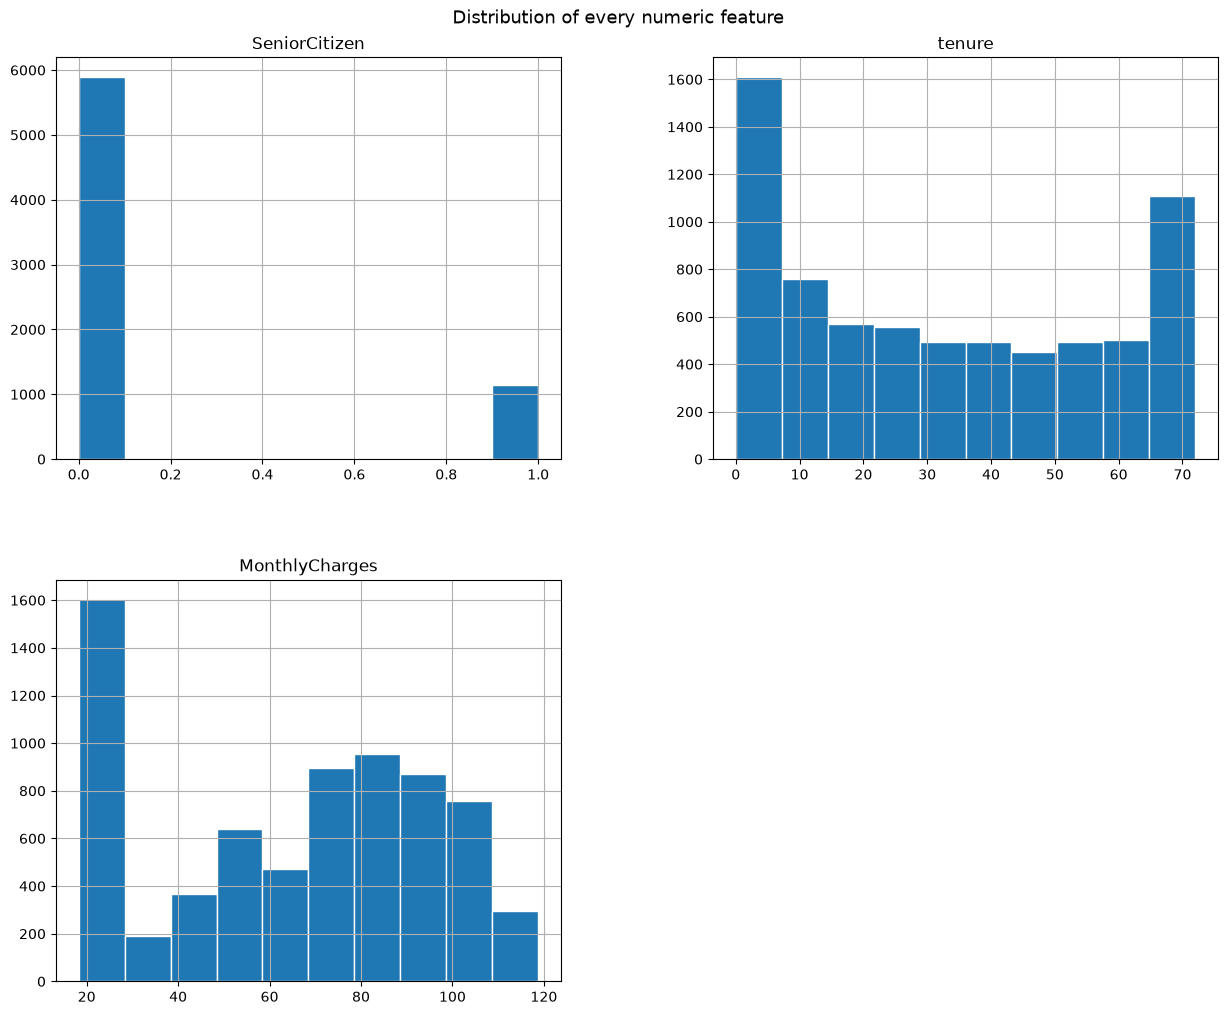

In [9]:
# One histogram per numeric feature
axes = df.select_dtypes(include=np.number).hist(figsize=(15, 12), edgecolor="white")
plt.suptitle("Distribution of every numeric feature", y=0.92, fontsize=13)
plt.show()

- I note that the monthly charge at 20 is the highest. 

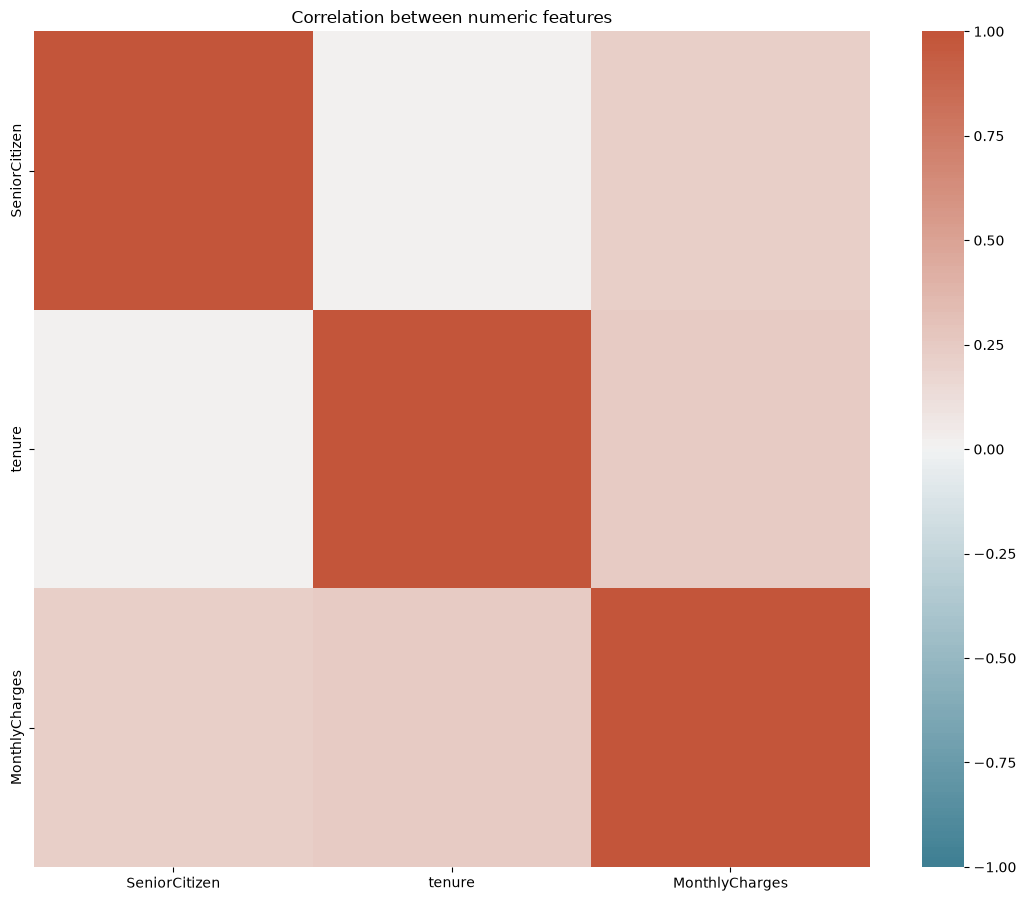

In [ ]:
# Correlation on numeric features
plt.figure(figsize=(11, 9))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, vmin=-1, vmax=1, center=0,
            cmap=sns.diverging_palette(220, 20, n=200), annot=False, square=True)
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.show()

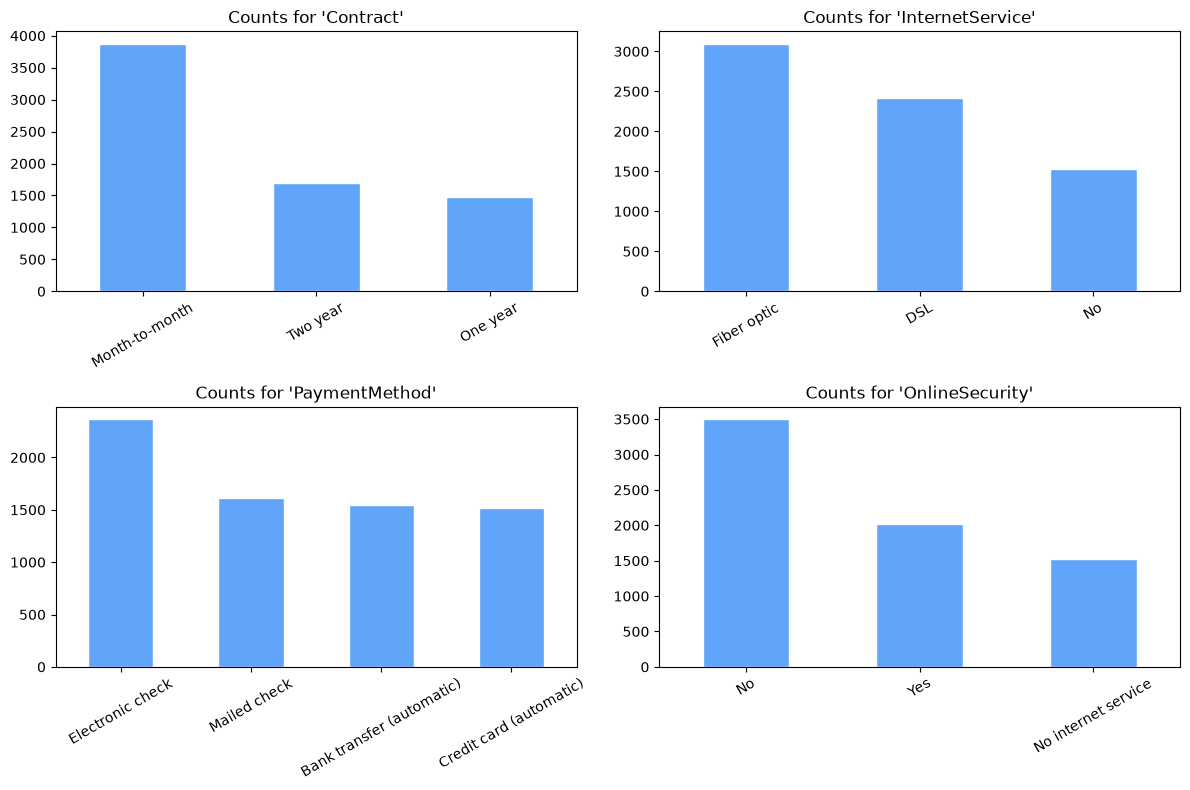

In [ ]:
# Histogram on few categorical features
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity"]):
    df[col].value_counts().plot(kind="bar", ax=ax, color="#60a5fa", edgecolor="white")
    ax.set_title(f"Counts for '{col}'")
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

- This gives the idea that month-to-month contract is most occured. Optic fiber for net, electronic check for payment, and no for online security. 

In [10]:
# Convert everything to numbers just for this check
df_corr = df.apply(lambda x: pd.factorize(x)[0])
df_corr["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}) # Ensure Yes=1

# Show correlation with Churn
print(df_corr.corr()["Churn"].sort_values(ascending=False).round(2))

Churn               1.00
SeniorCitizen       0.15
Partner             0.15
MultipleLines       0.04
MonthlyCharges      0.02
PhoneService        0.01
customerID          0.01
gender             -0.01
TotalCharges       -0.03
InternetService    -0.05
OnlineBackup       -0.07
tenure             -0.14
Dependents         -0.16
PaperlessBilling   -0.19
StreamingTV        -0.21
StreamingMovies    -0.21
PaymentMethod      -0.26
DeviceProtection   -0.28
TechSupport        -0.33
OnlineSecurity     -0.33
Contract           -0.40
Name: Churn, dtype: float64


- Here, The target Churn is more negatively correlated to most of the features. 

## Data quality checks

- I won't check for null values as I have already know there is 0 null value from the previous steps. 

In [7]:
# Duplicated rows
duplicates = df.duplicated().sum()
print(f"Total duplicated rows in the entire dataset: {int(duplicates)}")

if duplicates > 0:
    print("\nSample of duplicated rows (showing all occurrences):")
    display(df[df.duplicated(keep=False)].head())

Total duplicated rows in the entire dataset: 0


- There is 0 duplicated rows. 

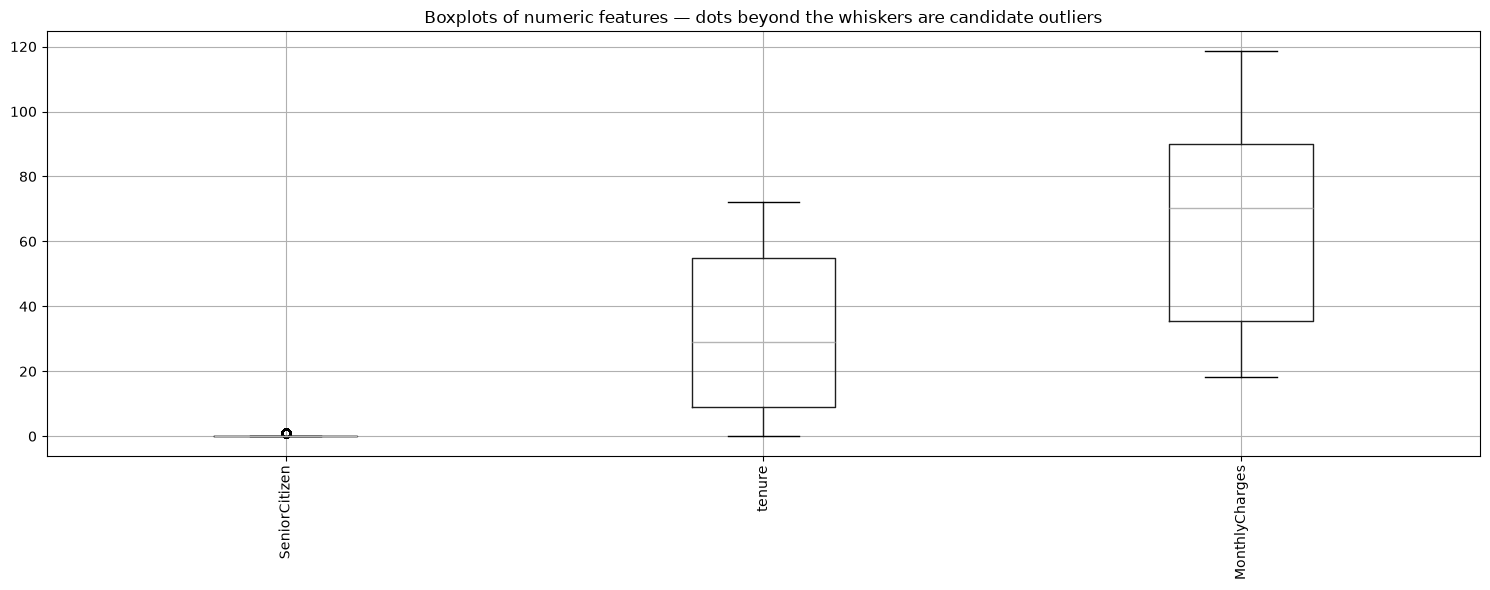

In [9]:
plt.figure(figsize=(15, 6))
df.select_dtypes(include=np.number).boxplot(rot=90)
plt.title("Boxplots of numeric features — dots beyond the whiskers are candidate outliers")
plt.tight_layout()
plt.show()

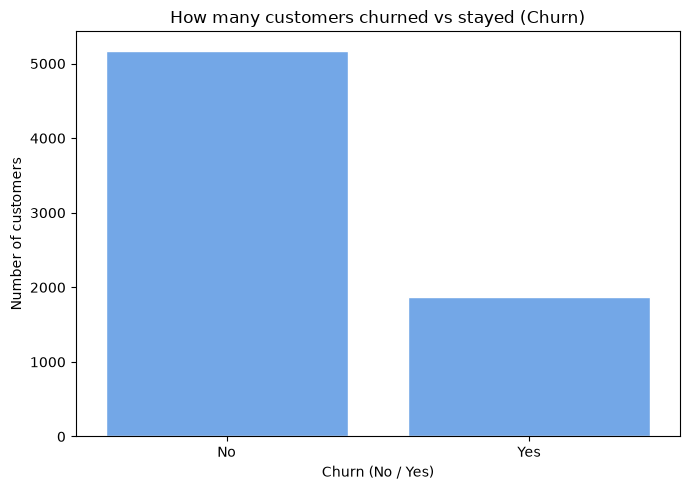

In [8]:
# target balanced? 
plt.figure(figsize=(7, 5))
sns.countplot(x="Churn", data=df, color="#60a5fa", edgecolor="white")
plt.title("How many customers churned vs stayed (Churn)")
plt.xlabel("Churn (No / Yes)"); plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

- There is clear impabalnce. 